In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [36]:
df = pd.read_csv('data/kc_house_data_original.csv')

In [37]:
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  object 
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long  

In [39]:
df.shape

(21613, 21)

In [40]:
df.isnull().sum()

id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

In [41]:
df['date'] = pd.to_datetime(df['date'])

In [42]:
df['date'].head()

0   2014-10-13
1   2014-12-09
2   2015-02-25
3   2014-12-09
4   2015-02-18
Name: date, dtype: datetime64[ns]

1.Create a scatter plot 

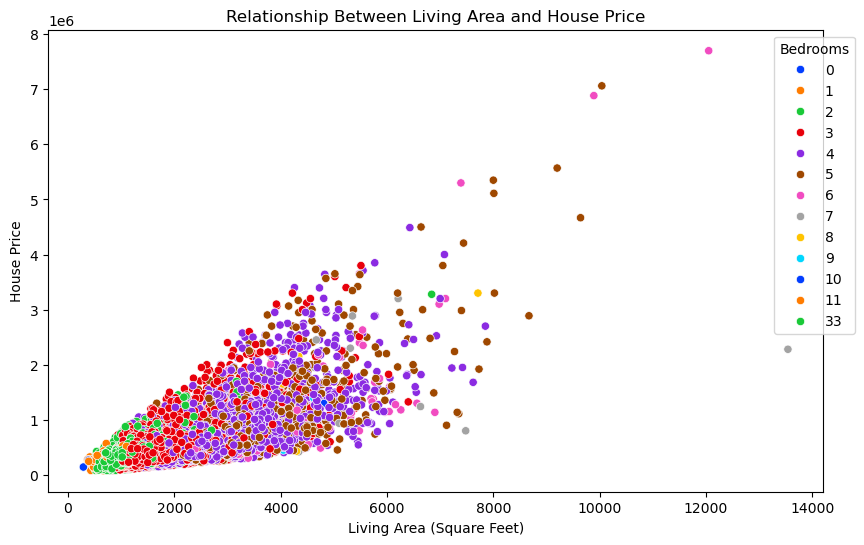

In [43]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x='sqft_living', y='price',
                hue='bedrooms', palette='bright',
                hue_order=sorted(df['bedrooms'].unique()))

plt.title('Relationship Between Living Area and House Price')
plt.xlabel('Living Area (Square Feet)')
plt.ylabel('House Price')
plt.legend(title='Bedrooms', bbox_to_anchor=(1.05, 1))

plt.show()

The scatter plot shows that house prices generally increase as living area increases. Most houses are concentrated in the smaller and medium-sized ranges, while a few larger homes have much higher prices. The different colors represent the number of bedrooms. Overall, living area appears to have a positive relationship with house prices.

2.Create a set of faceted histograms

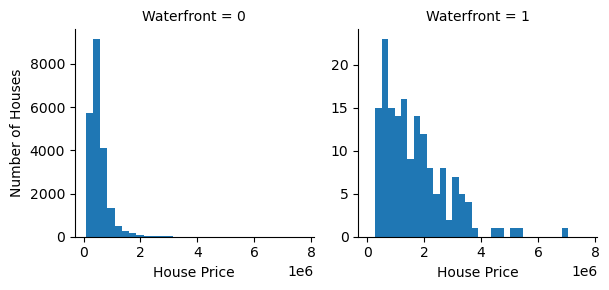

In [44]:
g = sns.FacetGrid(df, col='waterfront', sharey=False)

g.map(plt.hist, 'price', bins=30)

g.set_axis_labels('House Price', 'Number of Houses')

g.set_titles('Waterfront = {col_name}')

plt.show()

The histograms show how house prices vary between waterfront and non-waterfront properties. Most houses without waterfront are priced in the lower range, whereas waterfront houses have a wider range of prices. Overall, the graphs suggest that waterfront properties tend to have higher and more varied selling prices.

3.Create a time series plot showing the number of homes sold by month

In [45]:
df['month'] = df['date'].dt.to_period('M')

In [46]:
monthly_sales = df.groupby('month').size().reset_index(name='number_of_houses')

monthly_sales.head()

,month,number_of_houses
0,2014-05,1768
1,2014-06,2180
2,2014-07,2211
3,2014-08,1940
4,2014-09,1774


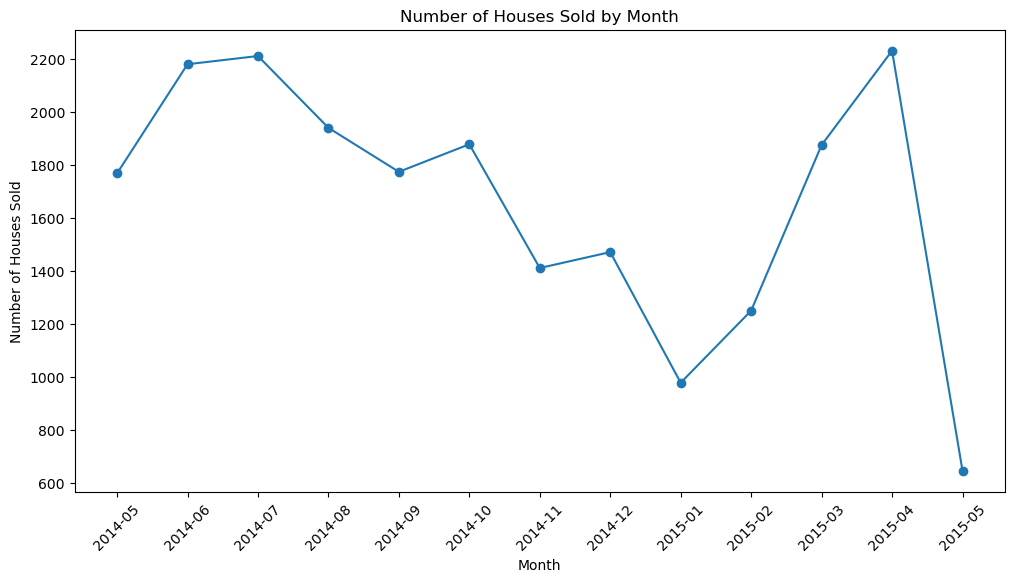

In [47]:
plt.figure(figsize=(12, 6))

plt.plot(monthly_sales['month'].astype(str),
         monthly_sales['number_of_houses'],
         marker='o')

plt.title('Number of Houses Sold by Month')
plt.xlabel('Month')
plt.ylabel('Number of Houses Sold')

plt.xticks(rotation=45)

plt.show()

The graph shows that monthly house sales went up and down throughout the period. Sales were higher during June and July 2014, then gradually decreased. They started to increase again in early 2015, reaching the highest point in April. Overall, the number of houses sold varied across the months.

4.a.creating box plot showing house prices by building grade

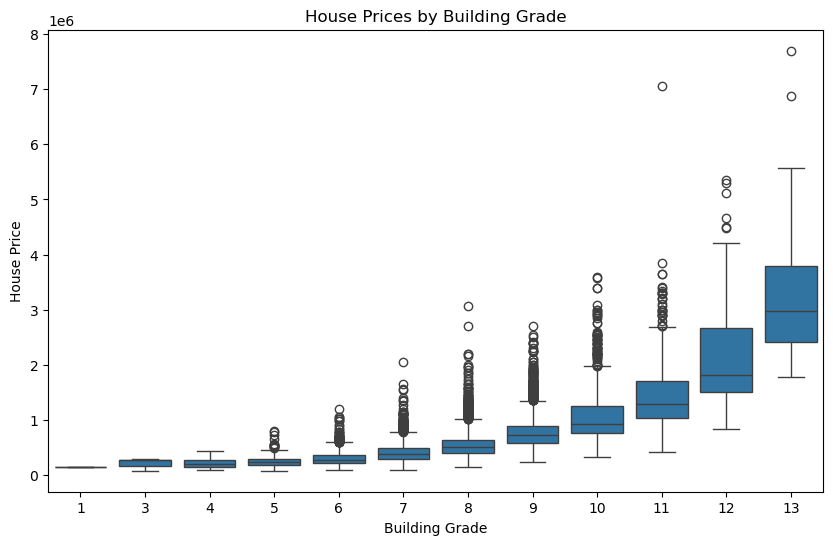

In [48]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df, x='grade', y='price')

plt.title('House Prices by Building Grade')
plt.xlabel('Building Grade')
plt.ylabel('House Price')

plt.show()

The box plot shows that houses with higher building grades generally have higher selling prices. The small circles above the boxes represent houses with unusually high prices compared to others in the same grade. These differences may be due to special features or larger property sizes. Overall, the graph suggests that building quality plays an important role in house prices.

b.House Price by Property Condition

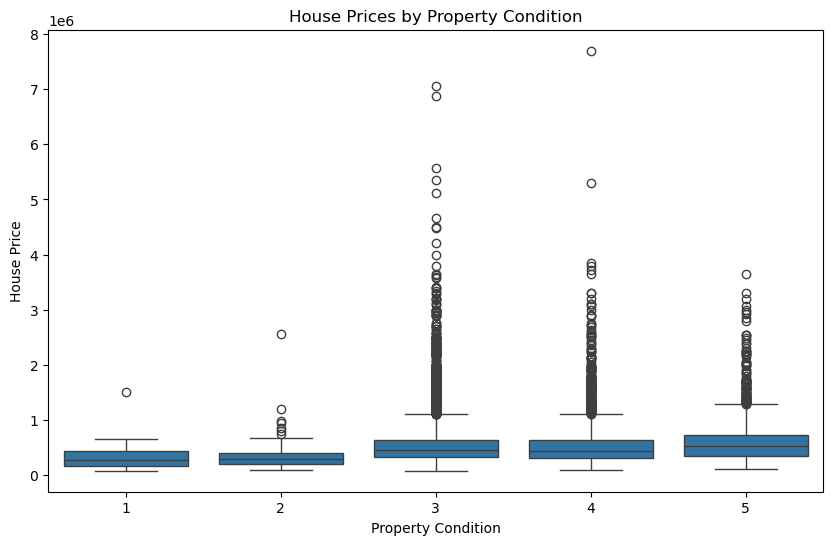

In [49]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df, x='condition', y='price')

plt.title('House Prices by Property Condition')
plt.xlabel('Property Condition')
plt.ylabel('House Price')

plt.show()


The graph compares house prices across different property condition levels. Houses in better condition generally have higher selling prices, while properties with lower condition ratings tend to have lower prices. Some houses also have unusually high prices compared to others. Overall, property condition seems to influence house prices, along with other factors.